# Do the reference dotplot's fine epithelial states exist in the human data?

**No re-clustering.** We use the existing `leiden_scVI_3.0` from the **04b latent**
(`data/interim/latent_human_epithelial.h5ad`) — the clustering the committed labels were
rolled up from — so anything we find maps straight back to the committed
`cell_type`/`subtype`. This notebook only reads and plots; it never touches the committed
pipeline.

Kernel: the `samap` env (`module load gcc/14.2.0-fasrc01` first if using the venv python).
Run the cells in order, and **check the output of the load/introspect cell** before plotting.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import scanpy as sc, anndata as ad, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
sc.settings.verbosity = 1

LATENT = "data/interim/latent_human_epithelial.h5ad"   # 04b -- leiden_scVI_3.0 valid HERE
CSV    = "resources/annotations/human_epithelial.csv"  # committed  cluster,label

In [2]:
# reference panel, transcribed from the dotplot -- eyeball against the figure.
# order = x-axis order; genes not in the object are dropped + reported below (not fatal).
GENES = ["MKI67","PCNA","BIRC5","MCM7","HSPA1A","DNAJB1","GADD45A","JUN","EGR1","ARC",
         "CCN1","CCN2","RRS1","LYAR","F3","TNFRSF12A","DKK1","SFN","FGF2","IFRD1","WWC1",
         "SEMA7A","MALT1","ADAMTS9","LDLR","ZNRF3","SH3RF2","WEE1","AMOTL1","PDGFA","EDN2",
         "CXCL8","CXCL3","PLAU","PLAUR","WNT7A","CD47","MMP7","IL32","KRT17","TNF","TNFAIP2",
         "IL1R1","CXCL10","VTCN1","IRAK2","CSF1","LIF","SAA1","SAA2","ESR1","PGR","SOX17",
         "LGR5","LGR4","COL1A2","ALDH1A1","CDH2","SCGB1D2","SCGB2A1","PTGS2","MT1F","CALB1",
         "PAX8","SERPINA5","C3","MUC5B","PAEP","PAX2","EGLN3","HILPDA","CCNO","E2F7","MCIDAS",
         "CDC20B","MAD2L1","CRELD2","DNAJB11","NEK2","PIFO","FOXJ1","RSPH1","TPPP3"]
ALIASES = {"CCN1": ["CYR61"], "CCN2": ["CTGF"]}   # common symbol drift
len(GENES)

83

## Load the 04b latent and see what's inside

Confirm a `leiden_scVI_*` column exists and that **gene expression is present** — if `X` is
only a handful of dims, this object stores embeddings only and you'll need to pull expression
from `lineages/human_epithelial.h5ad` instead (see note two cells down).

In [3]:
a = ad.read_h5ad(LATENT)
print(a)
leidens = [c for c in a.obs.columns if c.lower().startswith("leiden_scvi")]
print("leiden cols:", leidens)
print("X:", None if a.X is None else a.X.shape,
      "| raw:", a.raw is not None, "| layers:", list(a.layers.keys()))

AnnData object with n_obs × n_vars = 12179 × 36601
    obs: 'sample', 'species', 'timepoint', 'x_um_dbscan', 'y_um_dbscan', 'n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'pct_counts_ribo', 'doubletdetection_predicted_doublet', 'doubletdetection_doublet_score', 'cell_barcode', 'leiden_scVI_0.1', 'leiden_scVI_0.2', 'leiden_scVI_0.3', 'leiden_scVI_0.4', 'leiden_scVI_0.5', 'leiden_scVI_0.6', 'leiden_scVI_0.7', 'leiden_scVI_0.8', 'leiden_scVI_0.9', 'leiden_scVI_1.0', 'leiden_scVI_1.5', 'leiden_scVI_2.0', 'leiden_scVI_2.5', 'leiden_scVI_3.0', 'score_epithelial cells', 'score_endometrial fibroblasts', 'score_decidual cells', 'score_smooth muscle cells', 'score_immune cells', 'score_perivascular cells', 'celltype_ref', 'leiden_scVI_4.0', 'leiden_scVI_5.0', 'leiden_scVI_6.0', 'leiden_scVI_7.0', 'leiden_scVI_8.0', 'leiden_scVI_9.0', 'leiden_scVI_10.0', 'lineage', 'excluded'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'mito', 'highly_variable', 'highly_variable_ran

In [4]:
GROUP = "leiden_scVI_3.0" if "leiden_scVI_3.0" in a.obs else (leidens[-1] if leidens else None)
assert GROUP, "no leiden_scVI_* column found -- check the object"
a.obs[GROUP] = a.obs[GROUP].astype(str)
print(f"using leiden = {GROUP}  ({a.obs[GROUP].nunique()} clusters)")

def resolve(g):
    if g in a.var_names: return g
    for alt in ALIASES.get(g, []):
        if alt in a.var_names: return alt
    return None
present = [r for g in GENES if (r := resolve(g))]
missing = [g for g in GENES if resolve(g) is None]
print(f"{len(present)}/{len(GENES)} genes found.  missing: {missing}")
if len(present) < 0.5 * len(GENES):
    print("\n*** <50% found -- 04b latent likely stores embeddings only. Pull expression "
          "from lineages/human_epithelial.h5ad and transfer leiden by barcode instead. ***")

using leiden = leiden_scVI_3.0  (51 clusters)
83/83 genes found.  missing: []


## Map committed labels onto these cells, and cross-tab

Labels come straight from the committed CSV (`leiden -> label`). Clusters you **excluded** at
04c aren't in the CSV, so they land in `<excluded/unmapped>` — which is useful: you'll spot it
if a dropped cluster actually carries a reference-state signature.

In [5]:
csv = pd.read_csv(CSV, dtype=str)
lab = dict(zip(csv["cluster"], csv["label"]))
a.obs["committed_label"] = a.obs[GROUP].map(lab).fillna("<excluded/unmapped>")
print(f"CSV clusters: {len(lab)}  |  leiden clusters: {a.obs[GROUP].nunique()}")
ct = pd.crosstab(a.obs[GROUP], a.obs["committed_label"])
ct

CSV clusters: 51  |  leiden clusters: 51


committed_label,EXCLUDE,ciliated epithelium,epithelial cells
leiden_scVI_3.0,,,
0,0,0,209
1,463,0,0
10,0,0,289
11,238,0,0
12,0,0,405
13,0,0,327
14,0,0,288
15,0,0,267
16,0,0,129


## Fine view — reference panel over the existing leiden clusters

This is where a hidden state would show up: a marker block lighting up one (or a few) distinct
`leiden_scVI_3.0` clusters.

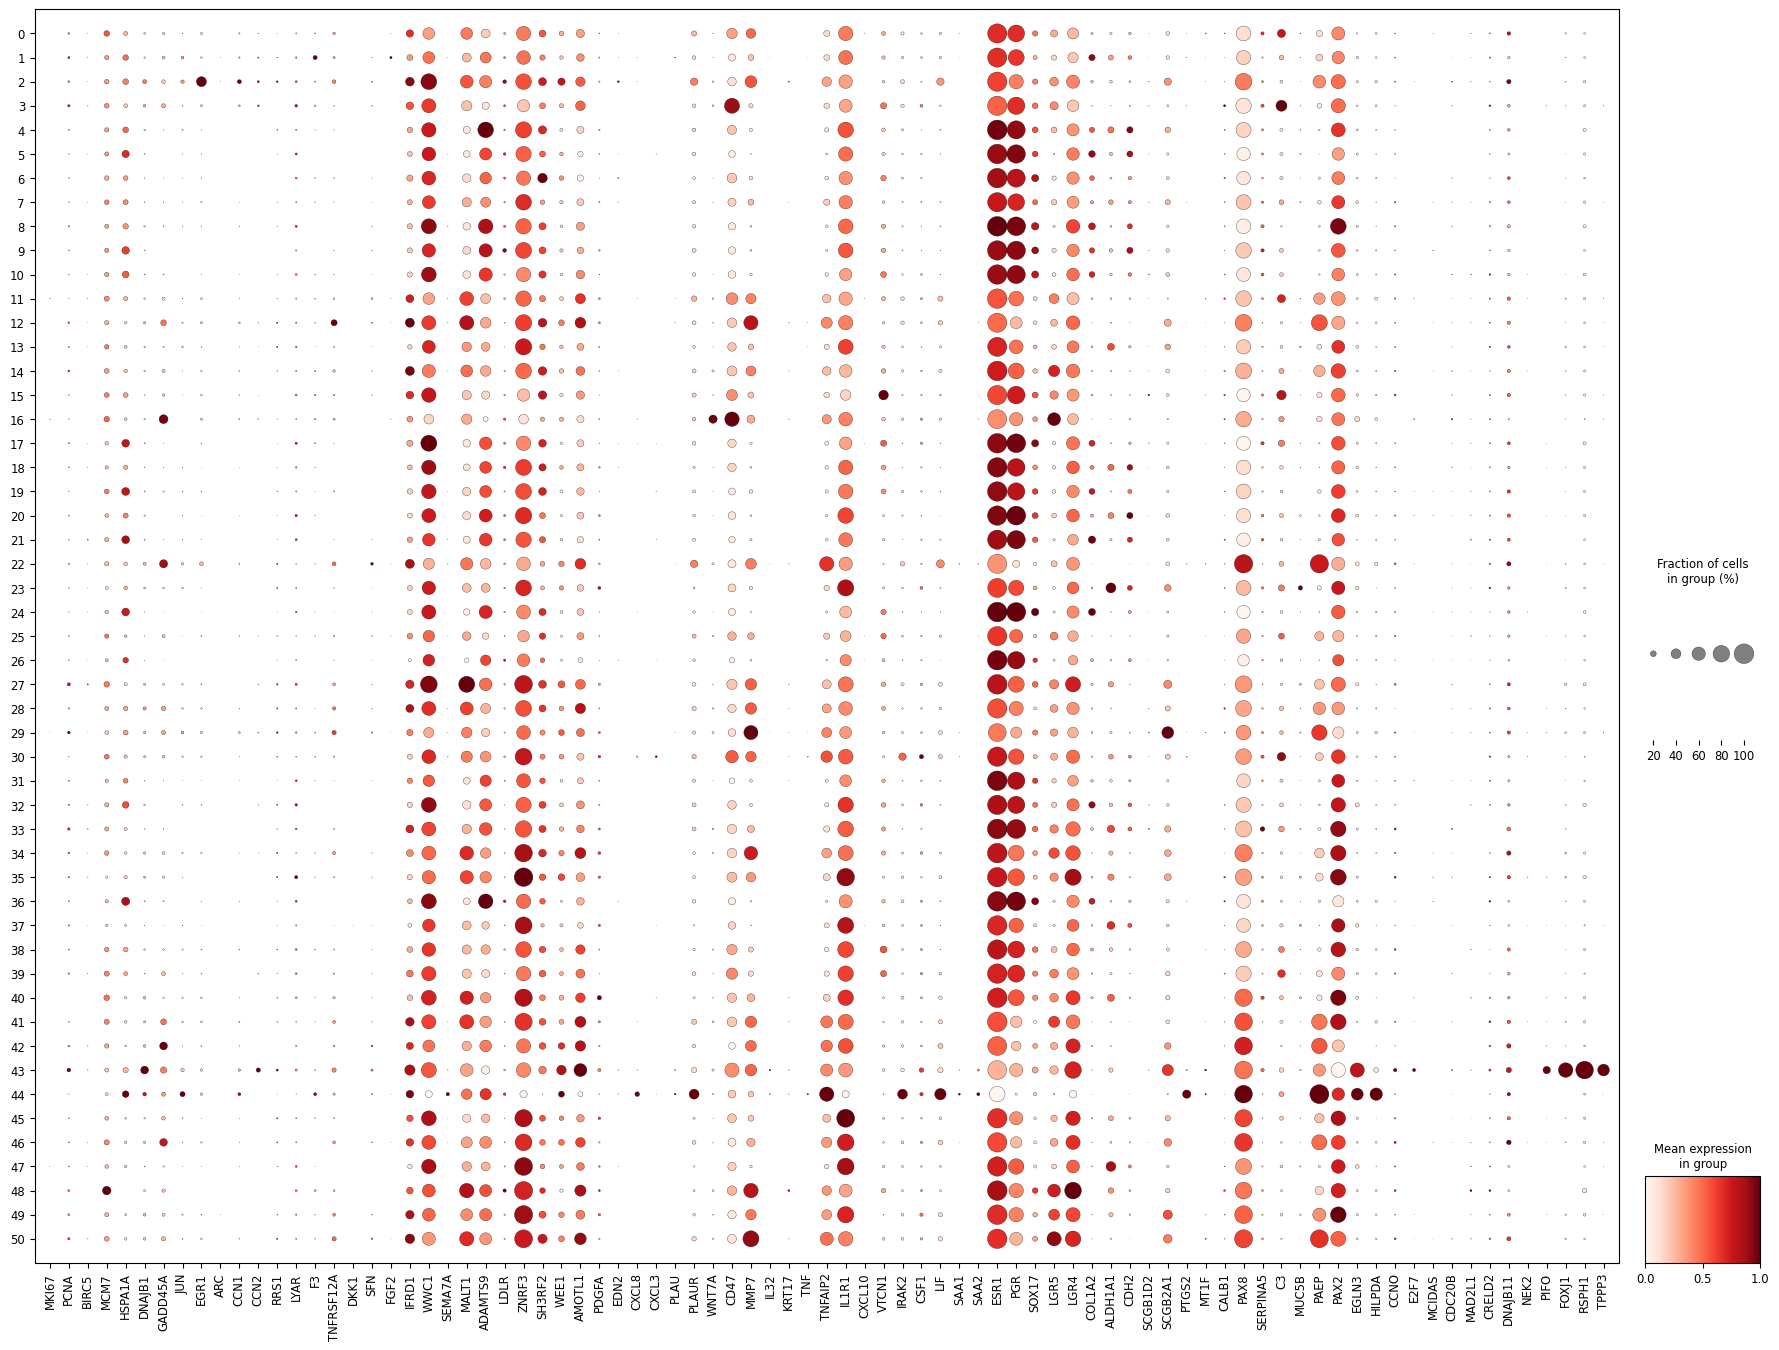

In [6]:
sc.pl.dotplot(a, present, groupby=GROUP, standard_scale="var",
              figsize=(len(present) * 0.22 + 4, a.obs[GROUP].nunique() * 0.28 + 2))

## Coarse view — same panel over the committed labels

Compare to the fine view: if a state's block is crisp in the leiden view but **smears together**
here, it's hiding inside a broad label.

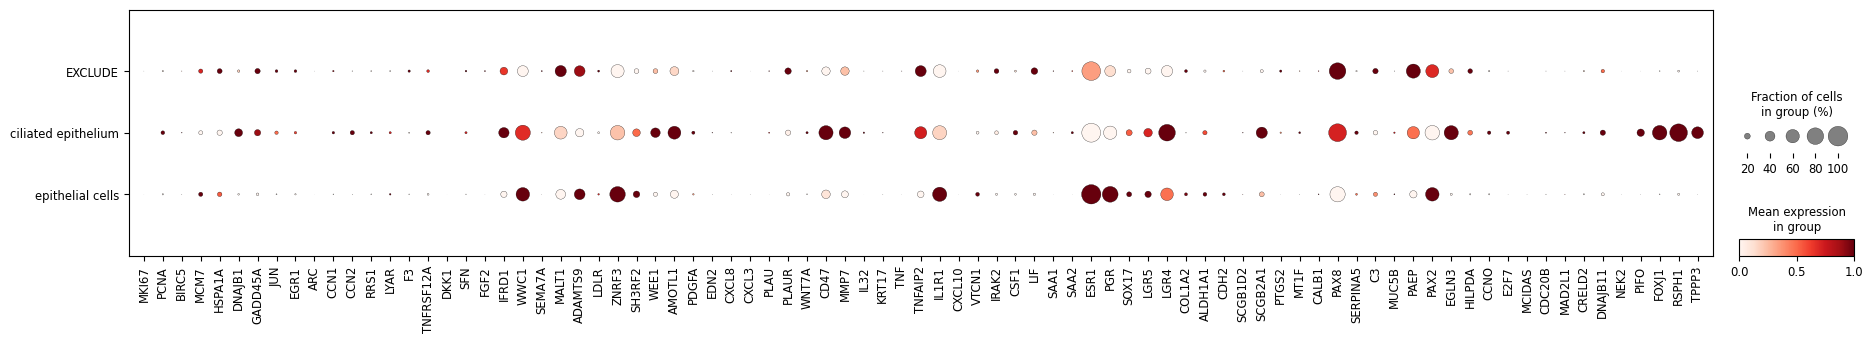

In [7]:
sc.pl.dotplot(a, present, groupby="committed_label", standard_scale="var",
              figsize=(len(present) * 0.22 + 4, a.obs["committed_label"].nunique() * 0.4 + 2))

## How to read this

- **Lights up in the fine view, smears in the coarse view** → that reference state is hiding inside a committed label → a re-write is worth considering.
- **Just as smeared in the fine view as the coarse one** → the states aren't separable in your data → leave the committed labels as-is.
- **`<excluded/unmapped>` row carries a clean signature** → a cluster you dropped at 04c may actually be one of these states — worth a second look.

**Sharper signal (optional):** instead of eyeballing marker blocks, turn each reference row into a marker module and score it per leiden cluster. Point me at the source paper's marker table and I'll add those cells.